# Term Project Milestone 1: Data Selection and EDA

Video game development is a high-cost, high-risk industry. Studios can spend years and millions of dollars building a new game, only to find that it underperforms in the market.  In an industry where the global market exceeds $180 billion annually, the ability to forecast sales before launch could provide a major competitive advantage and better investment.  Publishers and developers want to make informed decisions about which projects to greenlight, which platforms to target, and how to manage budgets efficiently.

The business problem addressed in this project is predicting a game’s global sales performance before release, based on its known characteristics. This potential predictive model could estimate sales potential using factors such as platform, genre, publisher, release year, and ESRB rating.  For example, certain genres may perform better on specific platforms or appeal to particular age demographics, while timing and platform trends could significantly influence overall demand.

The dataset selected for this project is Video Game Sales with Ratings data from Kaggle.  Reference URL: https://www.kaggle.com/datasets/rush4ratio/video-game-sales-with-ratings.  This dataset contains over 16,000 rows and 16 columns for game details such as Platform, Genre, Sales, and Review Scores.  

This analysis aims to uncover patterns between these attributes and actual sales figures.  By understanding which factors most strongly correlate with success, game publishers can better plan future releases and marketing strategies.  The target variable for the model will be Global_Sales.  Beyond predictive accuracy, the model’s insights could help reduce financial risk and improve strategic planning.  For example, smaller studios could use forecasts to decide whether to focus on niche genres with loyal audiences, while major publishers could use the model to prioritize high-potential titles for major investment.  Ultimately, data-driven forecasting offers a practical way to align creative ambition with commercial reality in one of the world’s most competitive entertainment industries.

## Graphical Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#read in the data from a local csv
game_sales = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

print(game_sales.info())
game_sales.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB
None


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
#transformation to remove rows with NAN in Year of Release
game_sales = game_sales.dropna(subset = ["Year_of_Release"])

#transformation to remove .0 from Year_of_Release
game_sales["Year_of_Release"] = game_sales["Year_of_Release"].astype(int)

#transformation to convert User Score to numeric
game_sales["User_Score"] = pd.to_numeric(game_sales["User_Score"], errors = "coerce")

game_sales.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### Graph 1: Distribution of Critic Scores

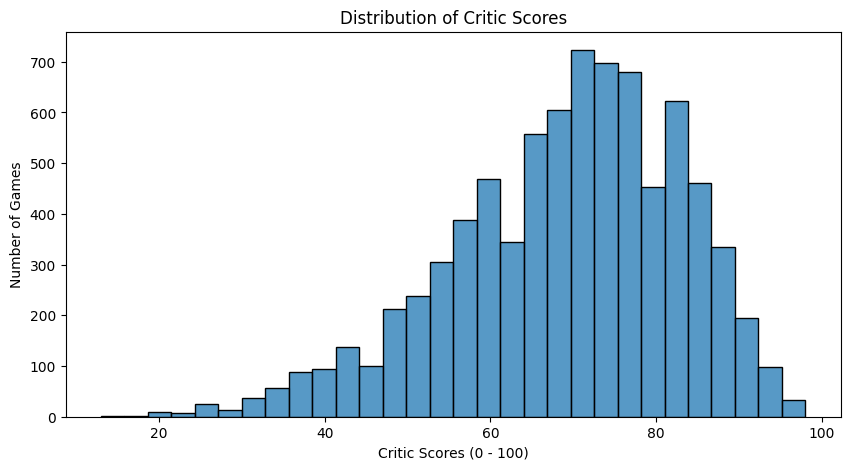

In [4]:
#plot histogram of Critic Score
plt.figure(figsize = (10, 5))
sns.histplot(game_sales["Critic_Score"], bins = 30)

plt.title("Distribution of Critic Scores")
plt.xlabel("Critic Scores (0 - 100)")
plt.ylabel("Number of Games")
plt.show()

In Graph 1, we can see that the majority of Critic Scores are in the higher half of the score range.  The peak of their scores are in the 70th percentile.

### Graph 2: Distribution of User Scores

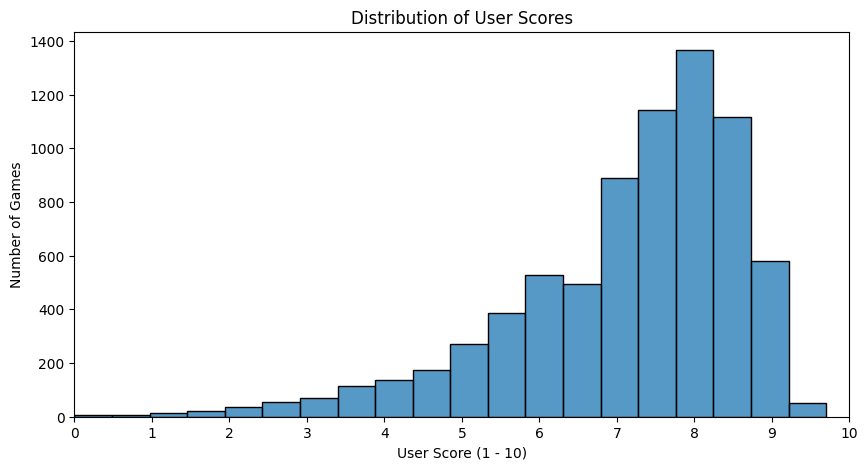

In [5]:
#use only valid scores between 0 and 10
filtered_scores = game_sales[(game_sales["User_Score"] >= 0) & (game_sales["User_Score"] <= 10)]

#plot histogram of User Score
plt.figure(figsize = (10, 5))
sns.histplot(data = filtered_scores, x = "User_Score", bins = 20)

plt.title("Distribution of User Scores")
plt.xlabel("User Score (1 - 10)")
plt.ylabel("Number of Games")

#set x-ticks and limit to 1-10 score range
plt.xticks(np.arange(0, 11, 1))
plt.xlim(0, 10)

plt.show()

In Graph 2, we get a view of the User Scores.  Similar to Graph 1, the majority of the User Scores are in the higher half of the score range.  The peak of User Scores is in the 80th percentile.  At first glance of Graph 1 and 2, Users seem to score games higher than Critics.

### Graph 3: Global Sales vs Critic Score

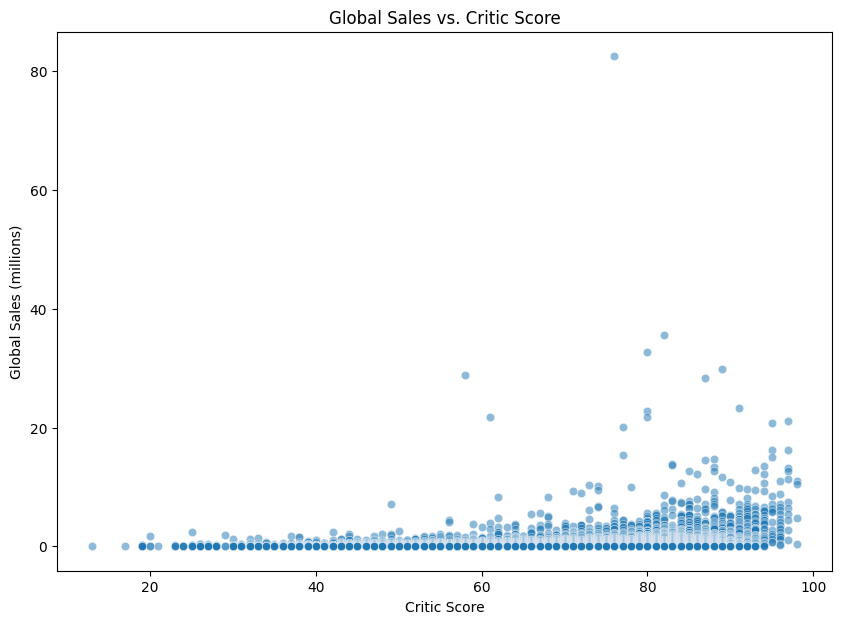

In [6]:
#plot scatterplot of Global Sales vs Critic Score
plt.figure(figsize = (10, 7))
sns.scatterplot(data = game_sales, x = "Critic_Score", y = "Global_Sales", alpha = 0.5)

plt.title("Global Sales vs. Critic Score")
plt.xlabel("Critic Score")
plt.ylabel("Global Sales (millions)")
plt.show()

Graph 3 shows us how Critic Scores line up agains Global Sales.  We can see a higher distribution in the higher half of Critic Score.  This leads us to believe that better critic scores will see better sales.

### Graph 4: Global Sales by Year of Release

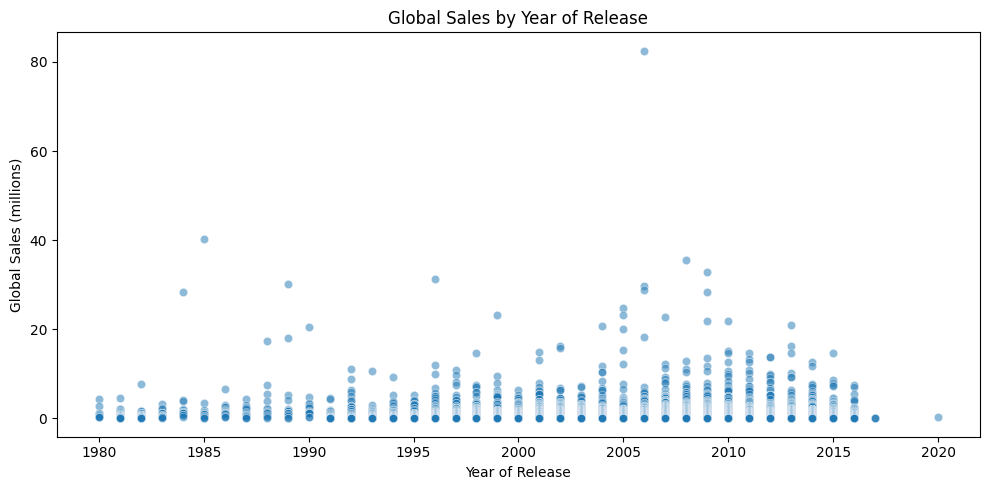

In [7]:
#plot scatterplot of Global Sales by Year of Release
plt.figure(figsize = (10, 5))
sns.scatterplot(data = game_sales, x = "Year_of_Release", y = "Global_Sales", alpha = 0.5)

plt.title("Global Sales by Year of Release")
plt.xlabel("Year of Release")
plt.ylabel("Global Sales (millions)")
plt.tight_layout()
plt.show()

Graph 4 shows how well games have sold globally between the years 1980 - 2016.  The 2020 outlier requires investigation.  You can see the trend where video game sales have continued to grow year by year.

### Graph 5: Global Sales by Publisher

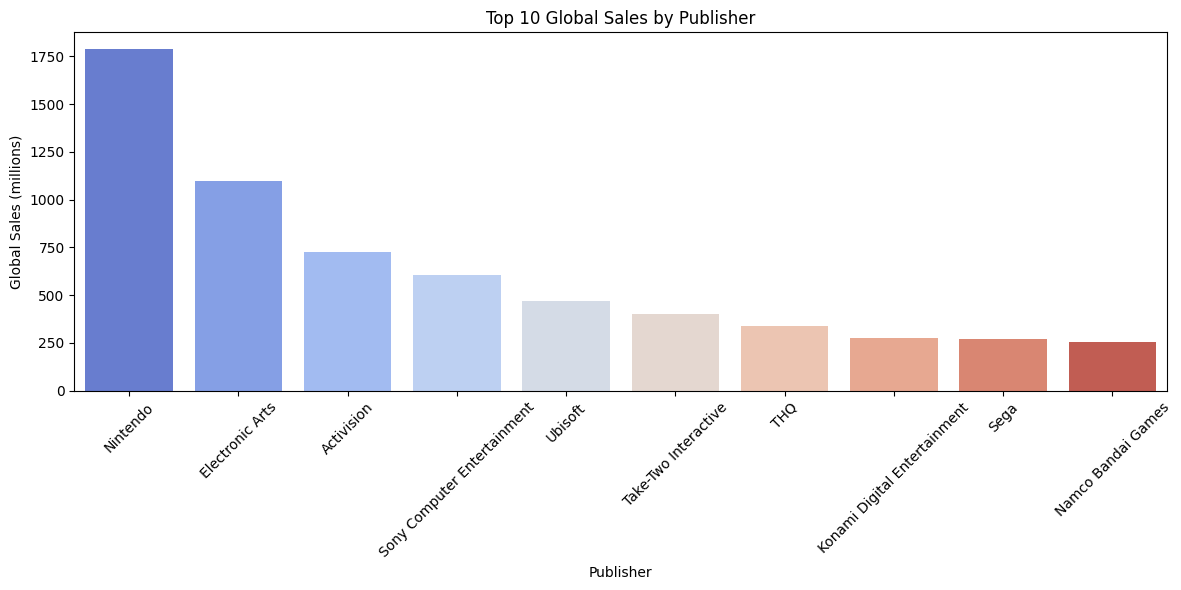

In [8]:
#aggregate sum of Global Sales per Publisher and display the Top 10
publisher_sales = (game_sales.groupby("Publisher")["Global_Sales"].sum().sort_values(ascending = False).head(10).reset_index())

#plot bar chart for Global Sales by Publisher
plt.figure(figsize = (12, 6))
sns.barplot(data = publisher_sales, x = "Publisher", y = "Global_Sales", hue = "Publisher", palette = "coolwarm", legend = False)

plt.title("Top 10 Global Sales by Publisher")
plt.xlabel("Publisher")
plt.ylabel("Global Sales (millions)")
plt.xticks(rotation = 45)  #rotate x ticks for readability 
plt.tight_layout()
plt.show()

Graph 5 shows us who the Top 10 Publishers are in Sales, since 1980.  Nintendo has been around much longer than most other publishers, so they have a comfortable lead over the other publishers.

### Graph 6: Global Sales by Genre

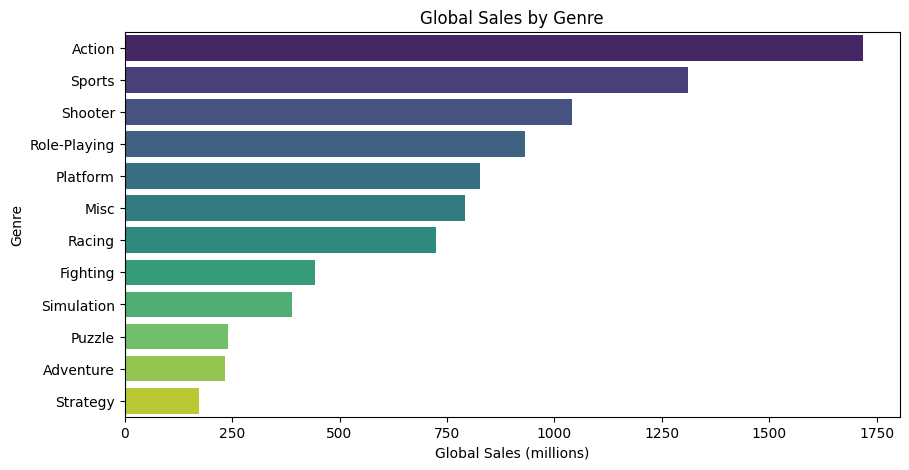

In [9]:
#aggregate sum of Global Sales per Genre
genre_sales = game_sales.groupby("Genre")["Global_Sales"].sum().sort_values(ascending = False).reset_index()

#plot bar chart for Global Sales by Genre
plt.figure(figsize = (10, 5))
sns.barplot(data = genre_sales, x = "Global_Sales", y = "Genre", hue = "Genre", palette = "viridis", legend = False)

plt.title("Global Sales by Genre")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Genre")
plt.show()

Graph 6 shows us Global Sales by Genre.  Action, Sports, and Shooters are the top three in sales.  Game developers looking for successful, new titles should consider entering one of those three genres.

### Graph 7: Global Sales by Platform

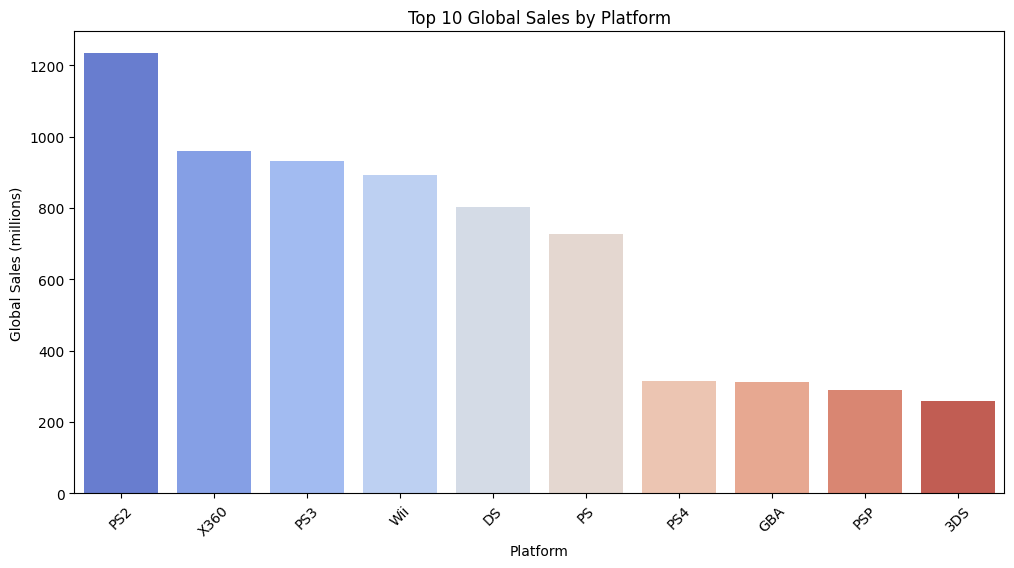

In [10]:
#aggregate sum of Global Sales per Platform and display the Top 10
platform_sales = (game_sales.groupby("Platform")["Global_Sales"].sum().sort_values(ascending = False).head(10).reset_index())

#plot barplot for Global Sales by Platform
plt.figure(figsize = (12, 6))
sns.barplot(data = platform_sales, x = "Platform", y = "Global_Sales", hue = "Platform", palette = "coolwarm", legend = False)        

plt.title("Top 10 Global Sales by Platform")
plt.xlabel("Platform")
plt.ylabel("Global Sales (millions)")
plt.xticks(rotation = 45)  #rotate x ticks for readability 
plt.show()

Graph 7 shows us how Game Platforms have sold over time.  The PS2, Xbox 360, and PS3 are the top three platforms.  It's interesting to get a view of the different systems by the industry giants: Nintendo (Wii, DS, GBA, 3DS), Playstation (PS2, PS3, PS, PS4, PSP), and Microsoft (Xbox360).

## Conclusion

In conclusion, we have gotten some good, initial insights into our video game sales dataset.  We have an early understanding of Critic Scores versus User Scores.  We have also gotten a glimpse at the Top Global Sales based on Critic Score, Year of Release, Publisher, Genre, and Platform.  These first insights will help in the next steps of building a model to predict sales from these features and measure its performance.  New features could also be considered where some can be combined together.

# Term Project Mielstone 2: Data Preparation

## 1. Drop any features that are not useful for your model building and explain why they are not useful.

In [4]:
#removing NA_Sales, EU_Sales, JP_Sales, and Other_Sales as they total up into Global_Sales.  name col not being used either.
game_sales = game_sales.drop(columns=["Name", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]) 

game_sales.head()

,Platform,Year_of_Release,Genre,Publisher,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii,2006,Sports,Nintendo,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,NES,1985,Platform,Nintendo,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Wii,2008,Racing,Nintendo,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii,2009,Sports,Nintendo,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,GB,1996,Role-Playing,Nintendo,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Perform any data extraction/selection steps.

In [5]:
#remove rows with missing target of Global Sales
game_sales = game_sales.dropna(subset = ["Global_Sales"])

game_sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16450 entries, 0 to 16718
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Platform         16450 non-null  object 
 1   Year_of_Release  16450 non-null  int64  
 2   Genre            16448 non-null  object 
 3   Publisher        16418 non-null  object 
 4   Global_Sales     16450 non-null  float64
 5   Critic_Score     7983 non-null   float64
 6   Critic_Count     7983 non-null   float64
 7   User_Score       7463 non-null   float64
 8   User_Count       7463 non-null   float64
 9   Developer        9907 non-null   object 
 10  Rating           9769 non-null   object 
dtypes: float64(5), int64(1), object(5)
memory usage: 1.5+ MB


## 3. Transform features if necessary.

__Note:__ Previous transformations done in Project Milestone 1, cell 3.

In [6]:
#scale Critic_Score to same range as User_Score. Critic_Score ranges from 1-100, while User_Score ranges from 1-10.
game_sales["Critic_Score"] = game_sales["Critic_Score"] / 10

game_sales.head()

,Platform,Year_of_Release,Genre,Publisher,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii,2006,Sports,Nintendo,82.53,7.6,51.0,8.0,322.0,Nintendo,E
1,NES,1985,Platform,Nintendo,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Wii,2008,Racing,Nintendo,35.52,8.2,73.0,8.3,709.0,Nintendo,E
3,Wii,2009,Sports,Nintendo,32.77,8.0,73.0,8.0,192.0,Nintendo,E
4,GB,1996,Role-Playing,Nintendo,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Engineer new useful features.

In [7]:
#create avg of Critic_Score and User_Score
game_sales["Total_Score"] = ((game_sales["Critic_Score"] + game_sales["User_Score"]) / 2)

#create diff of Critic_Score and User_Score
game_sales["Critic_to_User_Score_Diff"] = (game_sales["Critic_Score"] - game_sales["User_Score"])

#calculate decade from Year_of_Release
game_sales["Decade"] = (game_sales["Year_of_Release"] // 10) * 10

game_sales.head()

,Platform,Year_of_Release,Genre,Publisher,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating,Total_Score,Critic_to_User_Score_Diff,Decade
0,Wii,2006,Sports,Nintendo,82.53,7.6,51.0,8.0,322.0,Nintendo,E,7.80,-0.4,2000
1,NES,1985,Platform,Nintendo,40.24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1980
2,Wii,2008,Racing,Nintendo,35.52,8.2,73.0,8.3,709.0,Nintendo,E,8.25,-0.1,2000
3,Wii,2009,Sports,Nintendo,32.77,8.0,73.0,8.0,192.0,Nintendo,E,8.00,0.0,2000
4,GB,1996,Role-Playing,Nintendo,31.37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1990


## 5. Deal with missing data.

In [8]:
#numeric imputation for User_Score and Critic_Score
game_sales["User_Score"] = game_sales["User_Score"].fillna(game_sales["User_Score"].median())
game_sales["Critic_Score"] = game_sales["Critic_Score"].fillna(game_sales["Critic_Score"].median())

#categorical imputation for Publisher and Rating
game_sales["Publisher"] = game_sales["Publisher"].fillna("Unknown")
game_sales["Rating"] = game_sales["Rating"].fillna("Unknown")

game_sales.head()

,Platform,Year_of_Release,Genre,Publisher,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating,Total_Score,Critic_to_User_Score_Diff,Decade
0,Wii,2006,Sports,Nintendo,82.53,7.6,51.0,8.0,322.0,Nintendo,E,7.80,-0.4,2000
1,NES,1985,Platform,Nintendo,40.24,7.1,NaN,7.5,NaN,NaN,Unknown,NaN,NaN,1980
2,Wii,2008,Racing,Nintendo,35.52,8.2,73.0,8.3,709.0,Nintendo,E,8.25,-0.1,2000
3,Wii,2009,Sports,Nintendo,32.77,8.0,73.0,8.0,192.0,Nintendo,E,8.00,0.0,2000
4,GB,1996,Role-Playing,Nintendo,31.37,7.1,NaN,7.5,NaN,NaN,Unknown,NaN,NaN,1990


## 6. Create dummy variables if necessary.

In [9]:
#convert categorical columns into numeric for modeling
game_sales = pd.get_dummies(game_sales, columns = ["Platform", "Genre", "Rating"], drop_first = True)

#there are currently 579 Publishers, so simplifying to Top 10 
top_publishers = game_sales["Publisher"].value_counts().nlargest(10).index
game_sales["Publisher"] = game_sales["Publisher"].apply(lambda x: x if x in top_publishers else "Other")

#convert Publisher column into numeric for modeling
game_sales = pd.get_dummies(game_sales, columns = ["Publisher"], drop_first = True)

In [10]:
#final dataset from Milestone 2
game_sales

,Year_of_Release,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Total_Score,Critic_to_User_Score_Diff,Decade,...,Publisher_Electronic Arts,Publisher_Konami Digital Entertainment,Publisher_Namco Bandai Games,Publisher_Nintendo,Publisher_Other,Publisher_Sega,Publisher_Sony Computer Entertainment,Publisher_THQ,Publisher_Take-Two Interactive,Publisher_Ubisoft
0,2006,82.53,7.6,51.0,8.0,322.0,Nintendo,7.80,-0.4,2000,...,False,False,False,True,False,False,False,False,False,False
1,1985,40.24,7.1,NaN,7.5,NaN,NaN,NaN,NaN,1980,...,False,False,False,True,False,False,False,False,False,False
2,2008,35.52,8.2,73.0,8.3,709.0,Nintendo,8.25,-0.1,2000,...,False,False,False,True,False,False,False,False,False,False
3,2009,32.77,8.0,73.0,8.0,192.0,Nintendo,8.00,0.0,2000,...,False,False,False,True,False,False,False,False,False,False
4,1996,31.37,7.1,NaN,7.5,NaN,NaN,NaN,NaN,1990,...,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16714,2016,0.01,7.1,NaN,7.5,NaN,NaN,NaN,NaN,2010,...,False,False,False,False,True,False,False,False,False,False
16715,2006,0.01,7.1,NaN,7.5,NaN,NaN,NaN,NaN,2000,...,False,False,False,False,True,False,False,False,False,False
16716,2016,0.01,7.1,NaN,7.5,NaN,NaN,NaN,NaN,2010,...,False,False,False,False,True,False,False,False,False,False
16717,2003,0.01,7.1,NaN,7.5,NaN,NaN,NaN,NaN,2000,...,False,False,False,False,True,False,False,False,False,False


# Term Project Mielstone 3: Model Building and Evaluation

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

## Additional Transformations based on Milestone 2 feedback

In [12]:
#remove additional columns that aren't needed
game_sales = game_sales.drop(columns=["Critic_Count", "User_Count"]) 

#rerun calculations for Total_Score and Critic_Score after imputation from Milestone 2 Step 5
game_sales["Total_Score"] = ((game_sales["Critic_Score"] + game_sales["User_Score"]) / 2)
game_sales["Critic_to_User_Score_Diff"] = (game_sales["Critic_Score"] - game_sales["User_Score"])

#replace Developer NaNs with Unknown
game_sales["Developer"] = game_sales["Developer"].fillna("Unknown")

#convert Developer column into numeric for modeling
game_sales = pd.get_dummies(game_sales, columns = ["Developer"], drop_first = True)

game_sales.head()

,Year_of_Release,Global_Sales,Critic_Score,User_Score,Total_Score,Critic_to_User_Score_Diff,Decade,Platform_3DO,Platform_3DS,Platform_DC,...,Developer_id Software,"Developer_id Software, Nerve Software","Developer_id Software, Raven Software",Developer_n-Space,Developer_neo Software,Developer_odenis studio,Developer_oeFun,Developer_puzzle.tv,Developer_syn Sophia,Developer_zSlide
0,2006,82.53,7.6,8.0,7.80,-0.4,2000,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1985,40.24,7.1,7.5,7.30,-0.4,1980,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2008,35.52,8.2,8.3,8.25,-0.1,2000,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,2009,32.77,8.0,8.0,8.00,0.0,2000,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1996,31.37,7.1,7.5,7.30,-0.4,1990,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## Train and evaluate Linear Regression model, Linear Regression with MinMax Scaler, and Random Forest

In [19]:
#split the data into a training and test set, where Global_Sales is the target
X = game_sales.drop(columns = ["Global_Sales"])
y = game_sales["Global_Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [20]:
#func to evaluate model
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred) 
    return r2, rmse, mae

In [21]:
#evaluate Linear Regression
lin_reg = LinearRegression()
r2_lr, rmse_lr, mae_lr = evaluate_model(lin_reg, X_train, y_train, X_test, y_test)

#create pipeline and evaluate Linear Regression with MinMax scaling
pipe_lr_scaled = Pipeline([("scaler", MinMaxScaler()), ("model", LinearRegression())])
r2_lr_scaled, rmse_lr_scaled, mae_lr_scaled = evaluate_model(pipe_lr_scaled, X_train, y_train, X_test, y_test)

In [23]:
#create RF pipeline
pipe_rf = Pipeline([("model", RandomForestRegressor(random_state = 42))])

#RF hyperparameter tuning
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20]}

#create cross validation
cv = KFold(n_splits = 5, shuffle = True, random_state = 42)

#create grid search for RF
gridsearch_rf = GridSearchCV(pipe_rf, rf_param_grid, cv = cv, scoring = "neg_root_mean_squared_error").fit(X_train, y_train)

In [24]:
#retrieve best model
best_rf = gridsearch_rf.best_estimator_

#evaluate RF
r2_rf, rmse_rf, mae_rf = evaluate_model(best_rf, X_train, y_train, X_test, y_test)

In [25]:
#summarize results
summary = pd.DataFrame({
    "Model": ["Linear Regression", "MinMax + Linear Regression",
        f"Best Model ({type(best_rf.named_steps['model']).__name__})"],
    "R²": [r2_lr, r2_lr_scaled, r2_rf],
    "RMSE": [rmse_lr, rmse_lr_scaled, rmse_rf],
    "MAE": [mae_lr, mae_lr_scaled, mae_rf]
})

summary

,Model,R²,RMSE,MAE
0,Linear Regression,0.186130,1.852369,0.557521
1,MinMax + Linear Regression,0.186130,1.852369,0.557521
2,Best Model (RandomForestRegressor),0.199575,1.837006,0.458764


## Conclusion/Observations

### Personally
I did a lot of trial and error with models and evaluation metrics going through this milestone.  Although I was able to figure out Exercise 9.2, it was more difficult than I thought to apply those lessons to my project.  My weakness is in the stats portion of this program, and I felt more challanged this week.  In addition, I want to explore efficiecies in the last 2 cells as it took over 10 mins to process.

### Project
As you see in the Summary above, the best model for the cleaned up video game sales data is Random Forest.  
- Linear Regression has an R2 score below zero, meaning it likely performs poorly.  The RMSE and MAE scores are high, indicating poor predictions of Global_Sales.
- Linear Regression with MinMax outcomes are similar to Linear Regression: It has higher R2, RMSE, and MAE scores showing another poorly performing model.
- Random Forest had a R2 score of .20.  This is a low score, but better than the other models and can explain 20% of variance in Global_Sales.  The RMSE and MAE scores comes in with smaller scores showing it is the better model.

Reasons for model selection:
- Linear Regression is simple and a good baseline
- Linear Regression with MinMax Scale helps evaluate whether scaling improves performance
- Random Forest captures non-linear relationships and provies feature importance metrics

Reasons for evaluation metrics:
- R2 helps determine the overall fit of the model to the data
- RMSE is useful for understanding typical error size
- MAE is less sensative to outlierss than RMSE and provides a robust view of prediction error

In conclusion, Random Forest performed the best compared to the other models.  Next steps should include fine tuning the RF model to improve results and efficiencies. 

# Final Project Submission

## Milestone 3 feedback:

But some of your metrics, e.g., your R^2 values don't seem right. Double check everything is correct there. 

I re-ran the Milestone 3 code and got different and better metric returns.  Previously, the R2, RMSE, and MAE showed extremely large values.  The updated output can now be found in cell 25.